[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_preevent/BA_L4_preevent.ipynb)

# BA_L4_preevent: The USDC/USDT Deviation before a Depeg Episode

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Median and interquartile range, across the 30 episodes of USDC priced in USDT beyond 15 basis points (January 2022 to 23 October 2026), of the absolute deviation in the 48 hours before the first breach hour, against the median over all hours. Data: EODHD hourly aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

For each episode (a breach hour, $|d_t| \geq 15$ bp, after 24 observed quiet hours; $d_t$ = USDC priced in USDT, in basis points), the absolute deviation $|d_t|$ in the 48 hours before its first breach hour.
The line is the median across episodes, the band the interquartile range; the dashed line is the median $|d_t|$ over all hours; the shaded window $[-24\,\text{h}, -1\,\text{h}]$ is the window in which an alarm must fire to count as a warning.

**Data:** EOD Historical Data (EODHD) hourly closing prices, January 2022 to 23 October 2026.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


In [6]:
def episodes(dd, th, quiet=24, ambiguous=False):
    """Episode starts: breach hours (|d| >= th) preceded by `quiet` hours that are all observed and below th.
    With ambiguous=True also returns the breach hours after a quiet spell that contains missing hours."""
    b = dd.abs() >= th
    valid = dd.notna()
    q = (valid & ~b).astype(float).rolling(quiet).sum().shift(1) == quiet
    start = b & valid & q
    if not ambiguous:
        return dd.index[start]
    nobreach = b.astype(float).rolling(quiet).sum().shift(1) == 0
    return dd.index[start], dd.index[b & valid & ~q & nobreach]

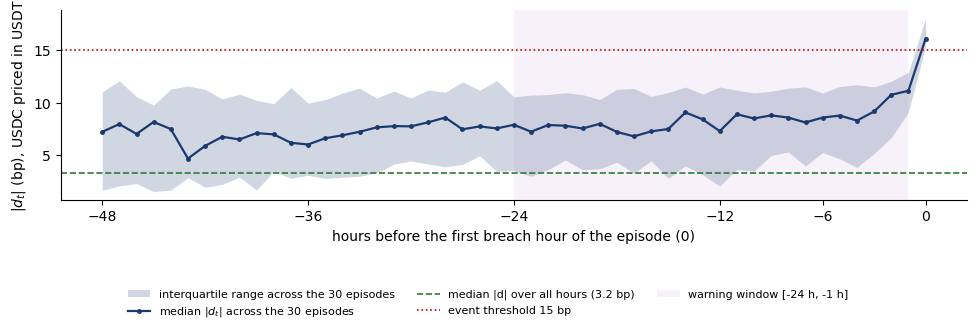

In [7]:
TH, hmax = 15, 48
ev15 = episodes(dh, TH)
PRE = pd.DataFrame({t0: dh.abs().reindex(pd.date_range(t0 - pd.Timedelta(hours=hmax), t0, freq='h')).values for t0 in ev15},
                   index=np.arange(-hmax, 1))
med_, q25_, q75_ = PRE.median(axis=1), PRE.quantile(0.25, axis=1), PRE.quantile(0.75, axis=1)
uncond = dh.abs().median()
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.fill_between(PRE.index, q25_, q75_, color=BLUE, alpha=0.2, lw=0, label=f'interquartile range across the {len(ev15)} episodes')
ax.plot(PRE.index, med_, color=BLUE, lw=1.6, marker='o', ms=2.5, label=rf'median $|d_t|$ across the {len(ev15)} episodes')
ax.axhline(uncond, color=GREEN, ls='--', lw=1.2, label=f'median |d| over all hours ({uncond:.1f} bp)')
ax.axhline(TH, color=RED, ls=':', lw=1.2, label='event threshold 15 bp')
ax.axvspan(-24, -1, color=ETH, alpha=0.08, lw=0, label='warning window [-24 h, -1 h]')
ax.set_xlabel('hours before the first breach hour of the episode (0)'); ax.set_ylabel(r'$|d_t|$ (bp), USDC priced in USDT')
ax.set_xticks([-48, -36, -24, -12, -6, 0])
save(fig, 'ba_l4_preevent', 0.2, ncol=3)

## Key numbers

In [8]:
print(f'median |d| over all hours: {uncond:.1f} bp')
print(f'median |d| across episodes: 48 h before {med_.loc[-48]:.1f} bp, 24 h before {med_.loc[-24]:.1f} bp, 6 h before {med_.loc[-6]:.1f} bp, '
      f'1 h before {med_.loc[-1]:.1f} bp, breach hour {med_.loc[0]:.1f} bp')
print(f'episodes with |d| >= 10 bp somewhere in [-24 h, -1 h]: {int((PRE.loc[-24:-1].max() >= 10).sum())} of {len(ev15)}')

median |d| over all hours: 3.2 bp
median |d| across episodes: 48 h before 7.2 bp, 24 h before 7.9 bp, 6 h before 8.6 bp, 1 h before 11.1 bp, breach hour 16.1 bp
episodes with |d| >= 10 bp somewhere in [-24 h, -1 h]: 25 of 30


**How to read it:** a day before the breach the median deviation, 7.9 bp, is already more than twice its level over all hours (3.2 bp), and it rises to 11.1 bp one hour before.
In 25 of 30 episodes $|d_t|$ reached 10 bp in the warning window. Deviations of 10–14 bp are also common without any breach, so a price rule pays for these warnings with false alerts.